In [3]:
import pandas as pd
import numpy as np
import re 

train_df = pd.read_csv("../data/processed_data/train.csv")
dev_df = pd.read_csv("../data/processed_data/dev.csv")

train_df[["Text_data", "Label"]].head()

,Text_data,Label
0,Finally Leaving : I finally left my husband. W...,moderate
1,Hate... : I hate myself! I hate my stupid fat ...,moderate
2,"I'm just a burden. : I'm annoying, stupid, ugl...",not depression
3,Self-Image : I wish sometimes that I wasn’t se...,not depression
4,I find it kind of funny seeing people freak ou...,moderate


In [2]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Create the sentiment analyser
sentiment_analyzer = SentimentIntensityAnalyzer()

example_text = train_df["Text_data"].iloc[0]

sentiment_scores = sentiment_analyzer.polarity_scores(
    str(example_text)
)
print("Example text:")
print(example_text)

print("\nSentiment scores:")
print(sentiment_scores)

Example text:
Finally Leaving : I finally left my husband. We still have to cohabitate in the same house for at least a year until we are able to get out from under it and sell. But I just came to the realization that being financially stable didn't make me less angry or more happy when the person I married, who is supposed to say I'm beautiful and smart and funny says all of those things less than a co-worker I have at work. I should have realized those things when we were dating but at that point I was just amazed anyone would want me. I don't like my coworker but he smiles when I walk by, laughs at my jokes, and everyday says "I just wanted you to know you are beautiful." I know it's probably borderline sexual harassment, and he's married as well so it's kind of skeevy but it's depressing that it got to the point of me needing to hear that validation from a stranger, because my husband says those things so infrequently. He gets me treats, and when I get him something in return he ac

In [4]:
def extract_features(text):
    text = str(text)

    # Basic text statistics
    words = re.findall(r"\b\w+\b", text.lower())
    sentences = re.split(r"[.!?]+", text)

    word_count = len(words)
    character_count = len(text)
    sentence_count = len([s for s in sentences if s.strip()])

    average_word_length = (
        np.mean([len(word) for word in words])
        if words else 0
    )

    # First-person singular pronouns
    first_person_words = {"i", "me", "my", "mine", "myself"}

    first_person_count = sum(
        word in first_person_words for word in words
    )

    first_person_ratio = (
        first_person_count / word_count
        if word_count else 0
    )

    # Punctuation features
    exclamation_count = text.count("!")
    question_count = text.count("?")

    repeated_punctuation_count = len(
        re.findall(r"[!?]{2,}", text)
    )

    # Sentiment features
    sentiment = sentiment_analyzer.polarity_scores(text)

    # Combine all features
    features = {
        "word_count": word_count,
        "character_count": character_count,
        "sentence_count": sentence_count,
        "average_word_length": average_word_length,
        "first_person_count": first_person_count,
        "first_person_ratio": first_person_ratio,
        "exclamation_count": exclamation_count,
        "question_count": question_count,
        "repeated_punctuation_count": repeated_punctuation_count,
        "sentiment_negative": sentiment["neg"],
        "sentiment_neutral": sentiment["neu"],
        "sentiment_positive": sentiment["pos"],
        "sentiment_compound": sentiment["compound"]
    }

    return features

In [5]:
train_features = pd.DataFrame(
    train_df["Text_data"].apply(extract_features).tolist()
)

train_features["Label"] = train_df["Label"].values
print("Feature dataset shape:", train_features.shape)
train_features.head()

Feature dataset shape: (5488, 14)


,word_count,character_count,sentence_count,average_word_length,first_person_count,first_person_ratio,exclamation_count,question_count,repeated_punctuation_count,sentiment_negative,sentiment_neutral,sentiment_positive,sentiment_compound,Label
0,426,2131,19,3.920188,44,0.103286,0,0,0,0.098,0.732,0.170,0.9891,moderate
1,130,608,13,3.530769,32,0.246154,4,0,1,0.426,0.465,0.109,-0.9965,moderate
2,27,127,2,3.444444,5,0.185185,0,0,0,0.350,0.570,0.080,-0.8591,not depression
3,84,434,7,4.071429,13,0.154762,0,0,0,0.172,0.746,0.082,-0.8128,not depression
4,104,524,4,3.980769,11,0.105769,0,0,0,0.127,0.753,0.120,0.2854,moderate


In [6]:
# Calculate average feature values for each class
class_means = train_features.groupby("Label").mean(numeric_only=True)
class_means.T

Label,moderate,not depression,severe
word_count,187.983612,118.447543,260.707965
character_count,931.977556,594.738658,1311.555752
sentence_count,11.409334,7.655009,16.286726
average_word_length,3.853131,4.087592,3.933714
first_person_count,21.545778,11.811909,29.396460
first_person_ratio,0.116896,0.092726,0.113711
exclamation_count,0.118632,0.362004,0.231858
question_count,0.718561,0.666352,1.148673
repeated_punctuation_count,0.030281,0.025520,0.069027
sentiment_negative,0.169248,0.148279,0.161699


Matplotlib is building the font cache; this may take a moment.


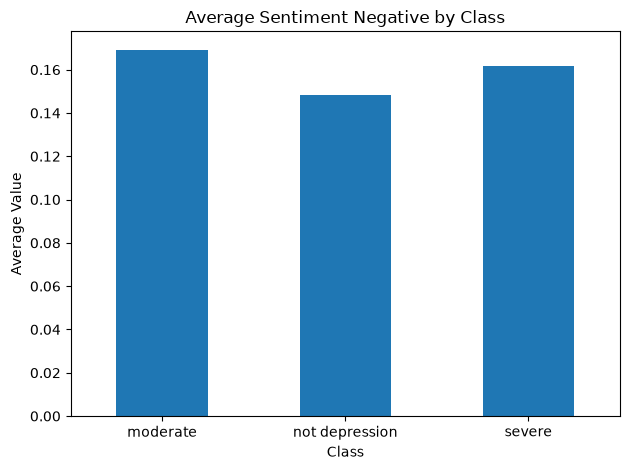

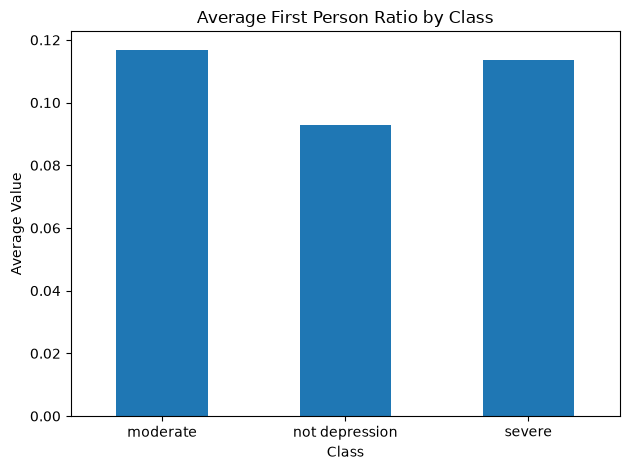

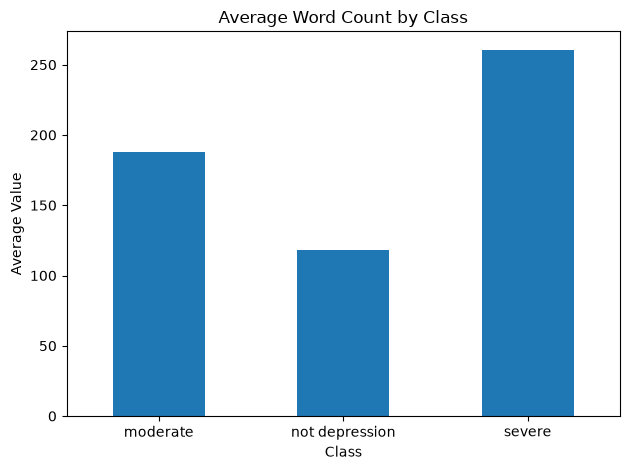

In [7]:
import matplotlib.pyplot as plt

features_to_plot = [
    "sentiment_negative",
    "first_person_ratio",
    "word_count"
]

for feature in features_to_plot:
    class_means[feature].plot(kind="bar")

    plt.title(f"Average {feature.replace('_', ' ').title()} by Class")
    plt.xlabel("Class")
    plt.ylabel("Average Value")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

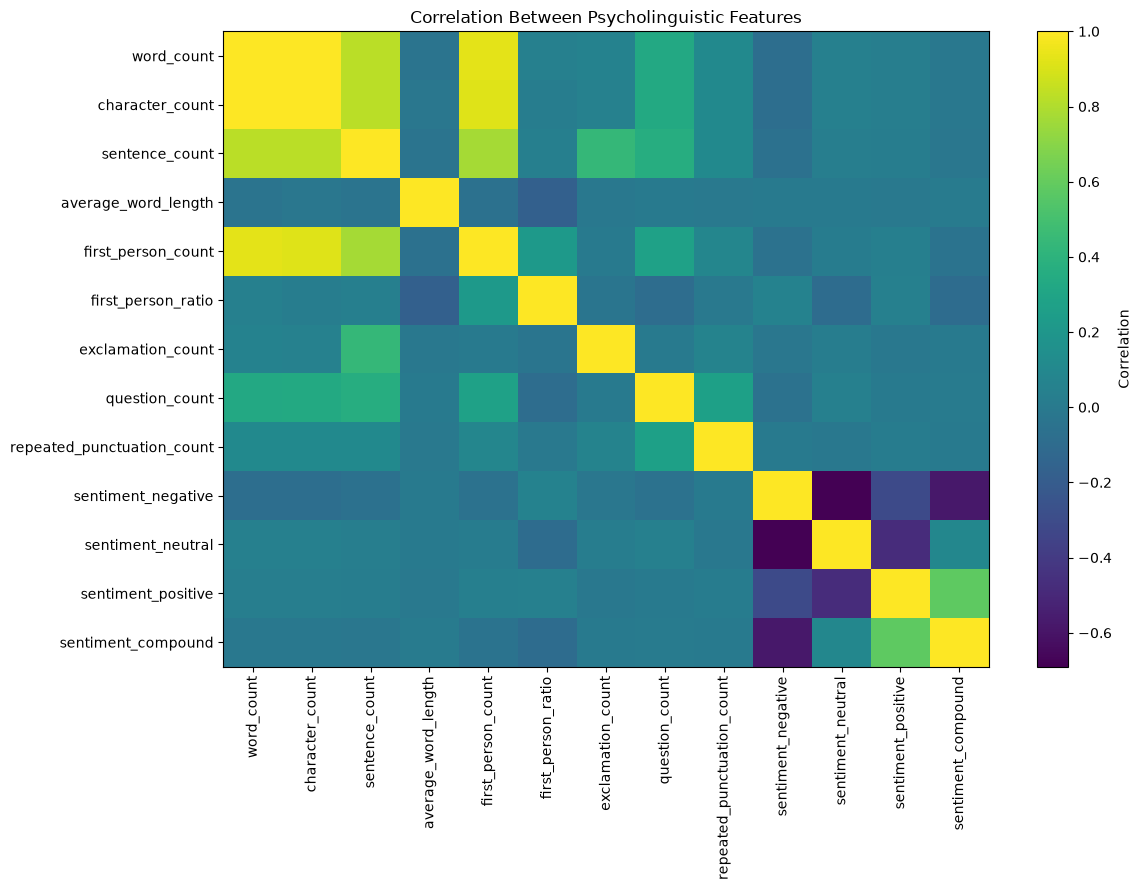

In [8]:
# Select numerical features only
numeric_features = train_features.drop(columns=["Label"])

# Calculate feature correlations
correlation_matrix = numeric_features.corr()

# Plot the correlation matrix
plt.figure(figsize=(12, 9))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Between Psycholinguistic Features")
plt.tight_layout()
plt.show()

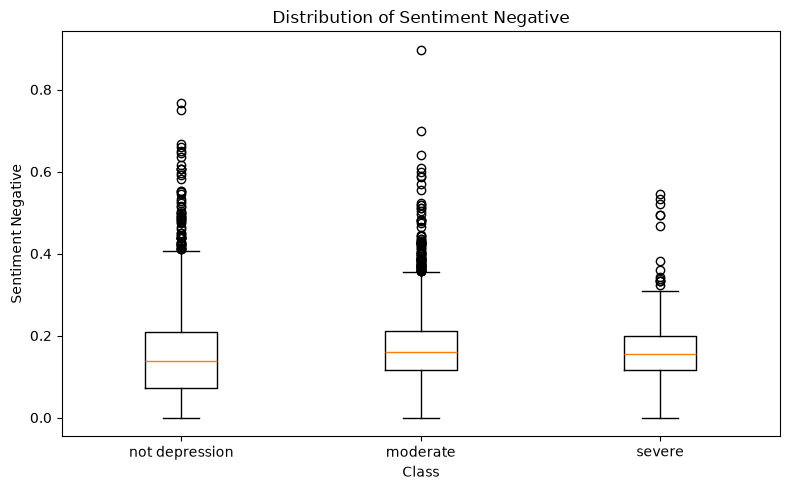

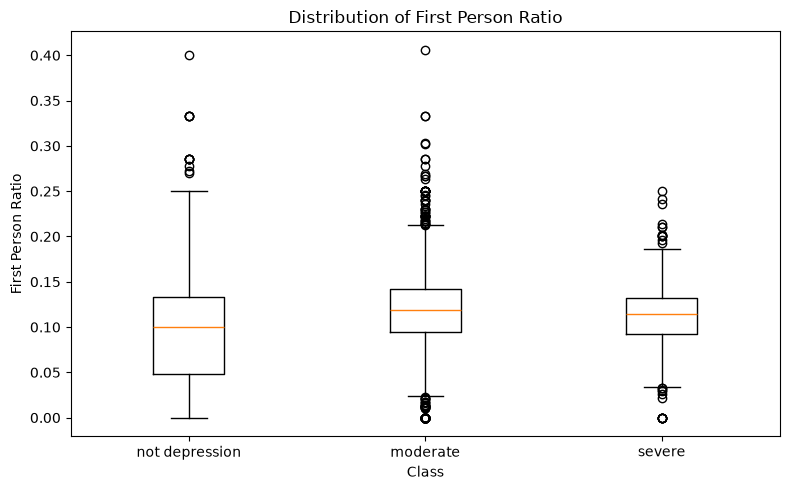

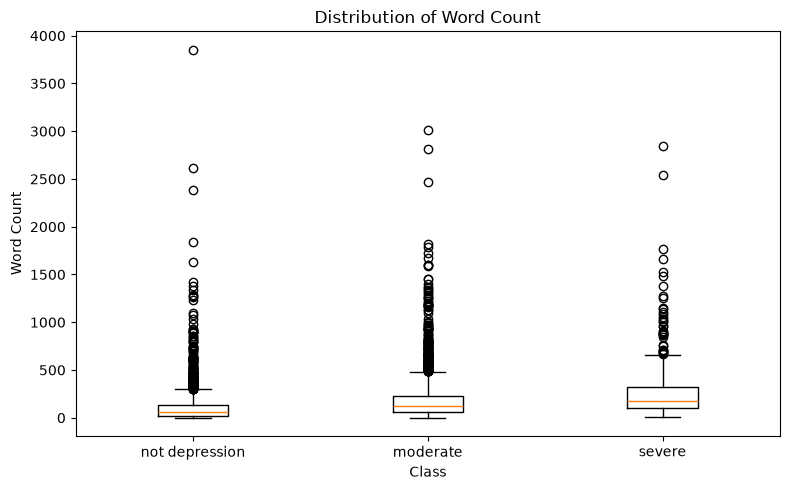

In [9]:
import matplotlib.pyplot as plt

features_to_compare = [
    "sentiment_negative",
    "first_person_ratio",
    "word_count"
]

class_order = [
    "not depression",
    "moderate",
    "severe"
]

for feature in features_to_compare:

    plt.figure(figsize=(8, 5))

    data_to_plot = [
        train_features.loc[
            train_features["Label"] == label, feature
        ].dropna()
        for label in class_order
    ]

    plt.boxplot(data_to_plot, tick_labels=class_order)

    plt.title(f"Distribution of {feature.replace('_', ' ').title()}")
    plt.xlabel("Class")
    plt.ylabel(feature.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report
)

# Separate features and labels
X_train = train_features.drop(columns=["Label"])
y_train = train_features["Label"]

# Extract the same features from development data
dev_features = pd.DataFrame(
    dev_df["Text_data"].apply(extract_features).tolist()
)

X_dev = dev_features
y_dev = dev_df["Label"]

print("Training features:", X_train.shape)
print("Development features:", X_dev.shape)

Training features: (5488, 13)
Development features: (1373, 13)


In [11]:
psycho_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=14
    ))
])

psycho_model.fit(X_train, y_train)

psycho_predictions = psycho_model.predict(X_dev)

In [12]:
print("Accuracy:",
      accuracy_score(y_dev, psycho_predictions))

print("Macro-F1:",
      f1_score(y_dev, psycho_predictions, average="macro"))

print("Weighted-F1:",
      f1_score(y_dev, psycho_predictions, average="weighted"))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_dev, psycho_predictions))

print("MCC:",
      matthews_corrcoef(y_dev, psycho_predictions))

print("\nClassification Report:\n")
print(classification_report(
    y_dev,
    psycho_predictions,
    zero_division=0
))

Accuracy: 0.5579024034959942
Macro-F1: 0.37752504064885023
Weighted-F1: 0.5186076122318409
Balanced Accuracy: 0.3989204606058651
MCC: 0.1717897612257395

Classification Report:

                precision    recall  f1-score   support

      moderate       0.56      0.76      0.65       703
not depression       0.55      0.43      0.48       529
        severe       0.00      0.00      0.00       141

      accuracy                           0.56      1373
     macro avg       0.37      0.40      0.38      1373
  weighted avg       0.50      0.56      0.52      1373



In [13]:
print("Actual development class distribution:")
print(y_dev.value_counts())

print("\nPredicted class distribution:")
print(pd.Series(psycho_predictions).value_counts())

print("\nConfusion matrix:")
from sklearn.metrics import confusion_matrix

print(confusion_matrix(
    y_dev,
    psycho_predictions,
    labels=["moderate", "not depression", "severe"]
))

Actual development class distribution:
Label
moderate          703
not depression    529
severe            141
Name: count, dtype: int64

Predicted class distribution:
moderate          952
not depression    418
severe              3
Name: count, dtype: int64

Confusion matrix:
[[537 163   3]
 [300 229   0]
 [115  26   0]]


In [14]:
psycho_weighted_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    ))
])

psycho_weighted_model.fit(X_train, y_train)

weighted_predictions = psycho_weighted_model.predict(X_dev)

In [17]:
print("Accuracy:",
      accuracy_score(y_dev, weighted_predictions))

print("Macro-F1:",
      f1_score(y_dev, weighted_predictions, average="macro"))

print("Weighted-F1:",
      f1_score(y_dev, weighted_predictions, average="weighted"))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_dev, weighted_predictions))

print("MCC:",
      matthews_corrcoef(y_dev, weighted_predictions))

print("\nClassification Report:\n")
print(classification_report(
    y_dev,
    weighted_predictions,
    zero_division=0
))

Accuracy: 0.46613255644573925
Macro-F1: 0.43010762656974766
Weighted-F1: 0.4790423875464861
Balanced Accuracy: 0.47467175598810646
MCC: 0.1749877349098122

Classification Report:

                precision    recall  f1-score   support

      moderate       0.60      0.39      0.47       703
not depression       0.52      0.56      0.54       529
        severe       0.20      0.47      0.28       141

      accuracy                           0.47      1373
     macro avg       0.44      0.47      0.43      1373
  weighted avg       0.53      0.47      0.48      1373

